# Chapter 32: Depth against width

Checks [chapter 32](../../book/32-depth-against-width.md). The models are **ReLU networks in one input and one
output**: the **tent layer** (two ReLU neurons, `2 relu(x) - 4 relu(x - 1/2)`) stacked deep, and **one-hidden-layer
ReLU networks** `sum(gain * relu(slope * x + bias))`, wide and shallow, including the ramp network of
`UniversalApproximation.lean`. Everything is NumPy in float64, seeded. These are measurements, not proofs: the
proofs are in `DepthSeparation.lean`, `UniversalApproximation.lean` and `KolmogorovArnold.lean`. Run every cell, top
to bottom. A failed check stops the notebook.

In [1]:
import sys
sys.path.append("../part1")

import itertools
import numpy as np
from scipy.optimize import linprog
import matplotlib.pyplot as plt
from common import use_style, save_figure, report, NEAREST, VERTICAL, BOUND, MODEL, BEFORE

use_style()
SEED = 32


def relu(values):
    return np.maximum(values, 0.0)


def apply_tent(inputs):
    return 2.0 * relu(inputs) - 4.0 * relu(inputs - 0.5)


def apply_tent_layers(inputs, layer_count):
    values = inputs
    for layer in range(layer_count):
        values = apply_tent(values)
    return values


def evaluate_shallow_network(gains, slopes, biases, inputs):
    """sum(gain[j] * relu(slope[j] * input + bias[j]) for each unit j): the EVALUATE_SHALLOW_NETWORK of the chapter."""
    inputs = np.asarray(inputs, dtype=float)
    return (gains * relu(slopes * inputs[..., None] + biases)).sum(axis=-1)


def count_pieces(values, tolerance=1e-9):
    """Number of straight pieces of the polyline through the samples: slope changes plus one. A kink between two
    samples changes the slope of two neighbouring steps, so neighbouring changes are counted once."""
    slopes = np.diff(values)
    scale = max(1.0, float(np.abs(slopes).max()))
    changed = np.abs(np.diff(slopes)) > tolerance * scale
    starts = changed & ~np.concatenate([[False], changed[:-1]])
    return int(starts.sum()) + 1

## Claim 1: the stack of tent layers (the example by hand)

Three tent layers, six neurons. Predicted: at `1/8` the three layers give `1/4`, `1/2`, `1`; at `2/8` they give
`1/2`, `1`, `0`; and on the nine grid points `0, 1/8, ..., 1` the stack gives `0, 1, 0, 1, 0, 1, 0, 1, 0`. These are
dyadic numbers, so the float arithmetic is exact and the comparison is `==`. Ten layers should give 512 peaks from 20
neurons. The claim fails if any value differs. These values come from evaluating the chapter's formula (from the formula), not from a fit or a trained model; the neuron counts are by construction and are printed as such, not counted as checks.

In [2]:
layer_values_at_one_eighth = [float(apply_tent_layers(1 / 8, layer_count)) for layer_count in (1, 2, 3)]
layer_values_at_two_eighths = [float(apply_tent_layers(2 / 8, layer_count)) for layer_count in (1, 2, 3)]
report("1/8 goes 1/4, 1/2, 1 and 2/8 goes 1/2, 1, 0 through three tent layers",
       layer_values_at_one_eighth == [0.25, 0.5, 1.0] and layer_values_at_two_eighths == [0.5, 1.0, 0.0],
       f"at 1/8: {layer_values_at_one_eighth}, at 2/8: {layer_values_at_two_eighths}")
grid_of_three_layers = np.arange(9) / 8
stack_on_grid = apply_tent_layers(grid_of_three_layers, 3)
report("three tent layers give 0, 1, 0, 1, 0, 1, 0, 1, 0 on the nine grid points",
       np.array_equal(stack_on_grid, np.arange(9) % 2), f"values {stack_on_grid.tolist()}")
peak_count = int(((stack_on_grid[1:-1] > stack_on_grid[:-2]) & (stack_on_grid[1:-1] > stack_on_grid[2:])).sum())
print(f"[by construction, cannot fail] the grid values just asserted have {peak_count} peaks")
print(f"[by construction, cannot fail] three tent layers have {2 * 3} neurons")
ten_layer_grid = np.arange(2 ** 10 + 1) / 2 ** 10
ten_layer_values = apply_tent_layers(ten_layer_grid, 10)
ten_layer_peaks = int(ten_layer_values[1::2].sum())
report("ten tent layers give 0, 1, 0, 1, ... on the 1025 grid points",
       np.array_equal(ten_layer_values, np.arange(2 ** 10 + 1) % 2),
       "from the formula, exact")
print(f"[by construction, cannot fail] the grid values just asserted have {ten_layer_peaks} peaks")
print(f"[by construction, cannot fail] ten tent layers have {2 * 10} neurons")

[PASS] 1/8 goes 1/4, 1/2, 1 and 2/8 goes 1/2, 1, 0 through three tent layers  (at 1/8: [0.25, 0.5, 1.0], at 2/8: [0.5, 1.0, 0.0])
[PASS] three tent layers give 0, 1, 0, 1, 0, 1, 0, 1, 0 on the nine grid points  (values [0.0, 1.0, 0.0, 1.0, 0.0, 1.0, 0.0, 1.0, 0.0])
[by construction, cannot fail] the grid values just asserted have 4 peaks
[by construction, cannot fail] three tent layers have 6 neurons
[PASS] ten tent layers give 0, 1, 0, 1, ... on the 1025 grid points  (from the formula, exact)
[by construction, cannot fail] the grid values just asserted have 512 peaks
[by construction, cannot fail] ten tent layers have 20 neurons


## Claim 2: wide and shallow pays one unit per turn (the counting behind `depth_separation`)

A one-hidden-layer network is a sum of units. On a stretch with no kink every unit is a straight line, so the sum
is. So `units` units make at most `units + 1` straight pieces on the interval from 0 to 1. Prediction: random
one-hidden-layer networks with `units` from 1 to 24 never show more than `units + 1` pieces; and when every kink is
placed inside the interval they reach `units + 1` exactly (so the count is not vacuous). The tent stack has
`2 ^ layer_count` pieces from `2 * layer_count` neurons. **Control:** the stack breaks the shallow count as soon as
`2 ^ layer_count > 2 * layer_count + 1`, which is from 3 layers on; if it did not, depth would buy nothing here. Two
kinds of shallow net, 20 draws each per unit count: gains, slopes and biases from a standard normal (kinks anywhere on
the line), and slopes of size 1 to 2 with each kink drawn uniformly in (0.05, 0.95).

In [3]:
generator = np.random.default_rng(SEED)
dense_inputs = np.linspace(0.0, 1.0, 100_001)
unit_counts = list(range(1, 25))
DRAWS = 20

most_pieces_random = []
most_pieces_kinks_inside = []
for unit_count in unit_counts:
    random_pieces = []
    inside_pieces = []
    for draw in range(DRAWS):
        gains = generator.standard_normal(unit_count)
        slopes = generator.standard_normal(unit_count)
        biases = generator.standard_normal(unit_count)
        random_pieces.append(count_pieces(evaluate_shallow_network(gains, slopes, biases, dense_inputs)))
        kinks = generator.uniform(0.05, 0.95, unit_count)
        slopes_inside = generator.choice([-1.0, 1.0], unit_count) * generator.uniform(1.0, 2.0, unit_count)
        biases_inside = -slopes_inside * kinks
        gains_inside = generator.uniform(0.5, 1.5, unit_count)
        inside_pieces.append(count_pieces(evaluate_shallow_network(gains_inside, slopes_inside, biases_inside, dense_inputs)))
    most_pieces_random.append(max(random_pieces))
    most_pieces_kinks_inside.append(max(inside_pieces))

excess = [pieces - unit_count - 1 for unit_count, pieces in zip(unit_counts, most_pieces_random)]
excess += [pieces - unit_count - 1 for unit_count, pieces in zip(unit_counts, most_pieces_kinks_inside)]
report("no shallow network, 1 to 24 units, 960 draws, has more than units + 1 pieces",
       max(excess) <= 0, f"largest pieces - (units + 1): {max(excess)}")
reached = [unit_count for unit_count, pieces in zip(unit_counts, most_pieces_kinks_inside) if pieces == unit_count + 1]
report("with every kink inside the interval the count units + 1 is reached for every unit count",
       len(reached) == len(unit_counts), f"reached at {len(reached)} of {len(unit_counts)} unit counts")

neuron_counts = [2 * layer_count for layer_count in range(1, 13)]
tent_pieces = []
for layer_count in range(1, 13):
    fine_grid = np.arange(4 * 2 ** layer_count + 1) / (4 * 2 ** layer_count)
    tent_pieces.append(count_pieces(apply_tent_layers(fine_grid, layer_count)))
report("control: the tent stack has 2^layer_count pieces from 2 * layer_count neurons",
       tent_pieces == [2 ** layer_count for layer_count in range(1, 13)], f"pieces {tent_pieces}")
beaten = [neurons for neurons, pieces in zip(neuron_counts, tent_pieces) if pieces > neurons + 1]
report("control: the tent stack beats the shallow count units + 1 from 3 layers on",
       beaten == neuron_counts[2:], f"first at {beaten[0]} neurons; at 24 neurons: {tent_pieces[-1]} pieces "
       f"against at most {24 + 1} for one hidden layer")

[PASS] no shallow network, 1 to 24 units, 960 draws, has more than units + 1 pieces  (largest pieces - (units + 1): 0)
[PASS] with every kink inside the interval the count units + 1 is reached for every unit count  (reached at 24 of 24 unit counts)
[PASS] control: the tent stack has 2^layer_count pieces from 2 * layer_count neurons  (pieces [2, 4, 8, 16, 32, 64, 128, 256, 512, 1024, 2048, 4096])
[PASS] control: the tent stack beats the shallow count units + 1 from 3 layers on  (first at 6 neurons; at 24 neurons: 4096 pieces against at most 25 for one hidden layer)


True

## Claim 3: fewer than `2 ^ layer_count` units cannot follow the stack within one half (`depth_separation`)

For `layer_count + 1` tent layers the grid has `2 ^ (layer_count + 1) + 1` points, and the stack is 0, 1, 0, 1, ...
there. The theorem says a shallow network within one half of it at every grid point has at least `2 ^ layer_count`
units. We test the **best** shallow network, not a random one. For a chosen set of kink positions, the smallest
possible largest grid error is a linear program: the network is `constant + linear + sum gain * relu(x - kink)` with
the gains free. (Units with no kink in the interval are straight lines and supply the constant and the linear part;
the program gets those free, so its fit is at least as good as any network with that many units, and a network
with fewer units than kinks is covered.)

**Prediction.** With fewer than `2 ^ layer_count` kinks the best error is at least `1/2`. For `layer_count` 1 and 2
the search is exhaustive over kink positions on a grid four times finer than the data grid for 0 to 3 kinks, and over
a coarser grid, of half the data spacing, for 4 or more kinks. The two kink counts therefore use different candidate grids, so the fewest kinks found for 4 or more is an upper bound on the true fewest. For `layer_count` 3 it is a random search then a local
search: it can only fail to find a good network, so it supports the claim and cannot prove it. The claim is counted
against if any set of fewer than `2 ^ layer_count` kinks gets below `1/2`. **Control:** with `2 ^ (layer_count + 1) - 1`
kinks, one at every interior grid point, the fit is exact (error 0), so the program does find good fits when they exist.

In [4]:
def get_best_grid_error(grid, targets, kink_positions):
    """Smallest possible largest error at the grid points: free constant, free slope, one ramp per kink."""
    columns = [np.ones_like(grid), grid] + [relu(grid - kink) for kink in kink_positions]
    design = np.stack(columns, axis=1)
    coefficient_count = design.shape[1]
    cost = np.zeros(coefficient_count + 1)
    cost[-1] = 1.0
    upper = np.hstack([design, -np.ones((len(grid), 1))])
    lower = np.hstack([-design, -np.ones((len(grid), 1))])
    constraint_matrix = np.vstack([upper, lower])
    constraint_bounds = np.concatenate([targets, -targets])
    bounds = [(None, None)] * coefficient_count + [(0, None)]
    result = linprog(cost, A_ub=constraint_matrix, b_ub=constraint_bounds, bounds=bounds, method="highs")
    return float(result.fun)


search_generator = np.random.default_rng(SEED + 1)
best_error_by_kinks = {}
for layer_count in (1, 2):
    grid = np.arange(2 ** (layer_count + 1) + 1) / 2 ** (layer_count + 1)
    targets = apply_tent_layers(grid, layer_count + 1)
    assert np.array_equal(targets, np.arange(len(grid)) % 2)
    fine_candidates = np.arange(1, 4 * 2 ** (layer_count + 1)) / (4 * 2 ** (layer_count + 1))
    coarse_candidates = np.arange(1, 2 * 2 ** (layer_count + 1)) / (2 * 2 ** (layer_count + 1))
    best_error_by_kinks[layer_count] = {}
    for kink_count in range(0, 2 ** (layer_count + 1)):
        candidates = fine_candidates if kink_count <= 3 else coarse_candidates
        best = min(get_best_grid_error(grid, targets, kinks) for kinks in itertools.combinations(candidates, kink_count))
        best_error_by_kinks[layer_count][kink_count] = best
    below = {kink_count: error for kink_count, error in best_error_by_kinks[layer_count].items()
             if kink_count < 2 ** layer_count}
    report(f"layer_count {layer_count}: fewer than {2 ** layer_count} kinks never get within 1/2 of the stack",
           all(error >= 0.5 - 1e-9 for error in below.values()),
           f"best errors for 0 to {2 ** layer_count - 1} kinks: {[round(error, 3) for error in below.values()]}")
    exact_kinks = 2 ** (layer_count + 1) - 1
    report(f"control, layer_count {layer_count}: {exact_kinks} kinks (one per interior grid point) fit exactly",
           best_error_by_kinks[layer_count][exact_kinks] < 1e-9,
           f"error {best_error_by_kinks[layer_count][exact_kinks]:.2e}")

for layer_count, errors in best_error_by_kinks.items():
    fewest = min(kink_count for kink_count, error in errors.items() if error < 0.5 - 1e-9)
    print(f"layer_count {layer_count}: the theorem's lower bound is {2 ** layer_count} units; "
          f"the fewest kinks that got within 1/2 was {fewest}; best errors by kink count "
          f"{[round(error, 3) for error in errors.values()]}")

[PASS] layer_count 1: fewer than 2 kinks never get within 1/2 of the stack  (best errors for 0 to 1 kinks: [0.5, 0.5])
[PASS] control, layer_count 1: 3 kinks (one per interior grid point) fit exactly  (error 0.00e+00)


[PASS] layer_count 2: fewer than 4 kinks never get within 1/2 of the stack  (best errors for 0 to 3 kinks: [0.5, 0.5, 0.5, 0.5])
[PASS] control, layer_count 2: 7 kinks (one per interior grid point) fit exactly  (error 0.00e+00)
layer_count 1: the theorem's lower bound is 2 units; the fewest kinks that got within 1/2 was 3; best errors by kink count [0.5, 0.5, 0.5, 0.0]
layer_count 2: the theorem's lower bound is 4 units; the fewest kinks that got within 1/2 was 7; best errors by kink count [0.5, 0.5, 0.5, 0.5, 0.5, 0.5, 0.5, 0.0]


In [5]:
layer_count = 3
grid = np.arange(2 ** (layer_count + 1) + 1) / 2 ** (layer_count + 1)
targets = apply_tent_layers(grid, layer_count + 1)
candidates = np.arange(1, 4 * 2 ** (layer_count + 1)) / (4 * 2 ** (layer_count + 1))
kink_count = 2 ** layer_count - 1
best_found = np.inf
best_kinks = None
for draw in range(500):
    kinks = np.sort(search_generator.choice(candidates, kink_count, replace=False))
    error = get_best_grid_error(grid, targets, kinks)
    if error < best_found:
        best_found, best_kinks = error, kinks
best_before_local = best_found
for sweep in range(12):
    for index in range(kink_count):
        for shift in (-1 / 128, 1 / 128, -1 / 512, 1 / 512):
            trial = best_kinks.copy()
            trial[index] = float(np.clip(trial[index] + shift, 0.001, 0.999))
            error = get_best_grid_error(grid, targets, trial)
            if error < best_found - 1e-12:
                best_found, best_kinks = error, trial
exact_error = get_best_grid_error(grid, targets, grid[1:-1])
report(f"layer_count 3: with {kink_count} kinks (fewer than 2^3 = 8) the search never gets within 1/2",
       best_found >= 0.5 - 1e-9, f"best error found {best_found:.4f} (random search {best_before_local:.4f}, "
       f"then local search)")
report("control, layer_count 3: 15 kinks, one per interior grid point, fit exactly", exact_error < 1e-9,
       f"error {exact_error:.2e}")

[PASS] layer_count 3: with 7 kinks (fewer than 2^3 = 8) the search never gets within 1/2  (best error found 0.5000 (random search 0.5000, then local search))
[PASS] control, layer_count 3: 15 kinks, one per interior grid point, fit exactly  (error 0.00e+00)


True

## Claim 4: one hidden layer follows a gentle function with `2 * piece_count` units (`relu_network_close`)

The network is built by the theorem's recipe, not fitted, so the errors below are measured on that built network but the network itself is from the formula. It is the ramp network of the chapter: `model(0) + sum over pieces of piece_count * (model(right) - model(left))
* ramp`, where a ramp is `relu(x - left) - relu(x - right)`. That is `2 * piece_count` ReLU units (plus the constant
`model(0)`, which the theorem puts in the definition). **Prediction.** For targets of slope at most `slope_limit` the
largest error over 100001 inputs in [0, 1] is at most `2 * slope_limit / piece_count`, for `piece_count` from 1 to 640.
I also report `error * piece_count / slope_limit`; the bound says it is at most 2. The claim is counted against if any
error exceeds the bound. Targets: `sin(3 x)` (slope limit 3), `2 |x - 0.33|` (slope limit 2), and the three-layer tent
stack (slope limit 8). **Control:** `sin(30 x)` with the wrong slope limit 3, which breaks the hypothesis; the bound
must then fail, and the failure is reported.

In [6]:
def build_ramp_network(model, piece_count):
    """The units of INTERPOLATE_WITH_RELU: (constant, gains, kinks) for 2 * piece_count ReLU units."""
    edges = np.arange(piece_count + 1) / piece_count
    rises = model(edges[1:]) - model(edges[:-1])
    scale = piece_count * rises
    kinks = np.concatenate([edges[:-1], edges[1:]])
    gains = np.concatenate([scale, -scale])
    return float(model(0.0)), gains, kinks


def evaluate_ramp_network(network, inputs):
    constant, gains, kinks = network
    inputs = np.asarray(inputs, dtype=float)
    return constant + (gains * relu(inputs[..., None] - kinks)).sum(axis=-1)


def measure_error(model, piece_count, inputs):
    network = build_ramp_network(model, piece_count)
    return float(np.abs(evaluate_ramp_network(network, inputs) - model(inputs)).max())


evaluation_inputs = np.linspace(0.0, 1.0, 100_001)
targets = {
    "sin(3 x)": (lambda inputs: np.sin(3.0 * inputs), 3.0),
    "2 |x - 0.33|": (lambda inputs: 2.0 * np.abs(inputs - 0.33), 2.0),
    "three tent layers": (lambda inputs: apply_tent_layers(inputs, 3), 8.0),
}
PIECE_COUNTS = [1, 2, 5, 10, 20, 40, 60, 80, 160, 320, 640]
errors_by_target = {}
for name, (model, slope_limit) in targets.items():
    errors = [measure_error(model, piece_count, evaluation_inputs) for piece_count in PIECE_COUNTS]
    errors_by_target[name] = errors
    bounds = [2.0 * slope_limit / piece_count for piece_count in PIECE_COUNTS]
    ratio = max(error * piece_count / slope_limit for error, piece_count in zip(errors, PIECE_COUNTS))
    report(f"{name}: error <= 2 * slope_limit / piece_count for every piece_count",
           all(error <= bound + 1e-12 for error, bound in zip(errors, bounds)),
           f"largest error * piece_count / slope_limit = {ratio:.3f} (the bound says at most 2)")

wrong_model = lambda inputs: np.sin(30.0 * inputs)
wrong_errors = [measure_error(wrong_model, piece_count, evaluation_inputs) for piece_count in PIECE_COUNTS]
wrong_excess = [error / (2.0 * 3.0 / piece_count) for error, piece_count in zip(wrong_errors, PIECE_COUNTS)]
report("control: sin(30 x) judged with slope limit 3 breaks the bound",
       max(wrong_excess) > 1.0, f"error is {max(wrong_excess):.2f} times the claimed bound at worst "
       f"(piece_count {PIECE_COUNTS[int(np.argmax(wrong_excess))]})")

[PASS] sin(3 x): error <= 2 * slope_limit / piece_count for every piece_count  (largest error * piece_count / slope_limit = 0.309 (the bound says at most 2))


[PASS] 2 |x - 0.33|: error <= 2 * slope_limit / piece_count for every piece_count  (largest error * piece_count / slope_limit = 0.480 (the bound says at most 2))


[PASS] three tent layers: error <= 2 * slope_limit / piece_count for every piece_count  (largest error * piece_count / slope_limit = 0.500 (the bound says at most 2))


[PASS] control: sin(30 x) judged with slope limit 3 breaks the bound  (error is 1.62 times the claimed bound at worst (piece_count 5))


True

## Claim 5: the price of a slope, and the check-yourself numbers

Chapter examples: slope limit 2 and 40 pieces gives 80 units and error at most `2 * 2 / 40 = 0.1`; slope limit 3 and
60 pieces gives 120 units and error at most 0.1; and a Kolmogorov-Arnold node with three edge curves of slope limits 1,
2 and 3 and `piece_count` 100 is within `2 * (1 + 2 + 3) / 100 = 0.12`. Prediction: the measured errors are at most
these numbers. The slope 2 target is `2 |x - 0.33|`, the slope 3 target is `sin(3 x)`, and the node is
`sin(x) + sin(2 x) + sin(3 x)` on [0, 1], each curve replaced by its ramp network. Against the claim: any measured
error above 0.1 or 0.12.

In [7]:
slope_two_error = measure_error(targets["2 |x - 0.33|"][0], 40, evaluation_inputs)
report("slope limit 2, 40 pieces, 80 units: error within 0.1", slope_two_error <= 0.1,
       f"error {slope_two_error:.4f}, bound {2 * 2.0 / 40}, units {2 * 40}")
slope_three_error = measure_error(targets["sin(3 x)"][0], 60, evaluation_inputs)
report("slope limit 3, 60 pieces, 120 units: error within 0.1", slope_three_error <= 0.1,
       f"error {slope_three_error:.4f}, bound {2 * 3.0 / 60}, units {2 * 60}")
edge_curves = [lambda inputs: np.sin(inputs), lambda inputs: np.sin(2.0 * inputs), lambda inputs: np.sin(3.0 * inputs)]
node_exact = sum(curve(evaluation_inputs) for curve in edge_curves)
node_relu = sum(evaluate_ramp_network(build_ramp_network(curve, 100), evaluation_inputs) for curve in edge_curves)
node_error = float(np.abs(node_relu - node_exact).max())
report("Kolmogorov-Arnold node, slope limits 1, 2, 3, piece_count 100: within 0.12", node_error <= 0.12,
       f"error {node_error:.4f}, bound {2 * (1 + 2 + 3) / 100}")

[PASS] slope limit 2, 40 pieces, 80 units: error within 0.1  (error 0.0160, bound 0.1, units 80)
[PASS] slope limit 3, 60 pieces, 120 units: error within 0.1  (error 0.0003, bound 0.1, units 120)


[PASS] Kolmogorov-Arnold node, slope limits 1, 2, 3, piece_count 100: within 0.12  (error 0.0002, bound 0.12)


True

## Figures

The first figure shows Claims 2 and 3: pieces against neurons for the tent stack and for one hidden layer, and the
best grid error of one hidden layer against its number of kinks. The second shows Claim 4: the error of the ramp
network against the number of pieces, with the bound.

wrote book/figures/32-pieces-against-neurons.png


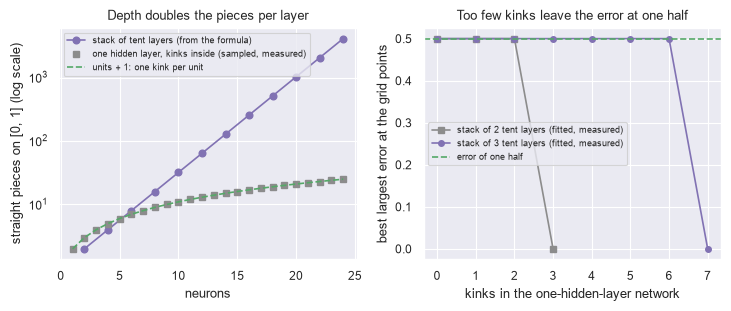

In [8]:
figure, (left_axis, right_axis) = plt.subplots(1, 2, figsize=(7.4, 3.2))
left_axis.plot(neuron_counts, tent_pieces, "o-", color=MODEL, label="stack of tent layers (from the formula)")
left_axis.plot(unit_counts, most_pieces_kinks_inside, "s", color=BEFORE, markersize=4,
               label="one hidden layer, kinks inside (sampled, measured)")
left_axis.plot(unit_counts, [unit_count + 1 for unit_count in unit_counts], "--", color=BOUND,
               label="units + 1: one kink per unit")
left_axis.set_yscale("log")
left_axis.set_xlabel("neurons")
left_axis.set_ylabel("straight pieces on [0, 1] (log scale)")
left_axis.set_title("Depth doubles the pieces per layer")
left_axis.legend(fontsize=6.5)

for layer_count, color, marker in ((1, BEFORE, "s"), (2, MODEL, "o")):
    errors = best_error_by_kinks[layer_count]
    kink_counts = list(errors)
    right_axis.plot(kink_counts, [errors[kink_count] for kink_count in kink_counts], marker + "-", color=color,
                    markersize=4, label=f"stack of {layer_count + 1} tent layers (fitted, measured)")
right_axis.axhline(0.5, color=BOUND, linestyle="--", label="error of one half")
right_axis.set_xlabel("kinks in the one-hidden-layer network")
right_axis.set_ylabel("best largest error at the grid points")
right_axis.set_title("Too few kinks leave the error at one half")
right_axis.legend(fontsize=6.5)
figure.tight_layout()
save_figure(figure, "32-pieces-against-neurons")
plt.show()

wrote book/figures/32-error-against-pieces.png


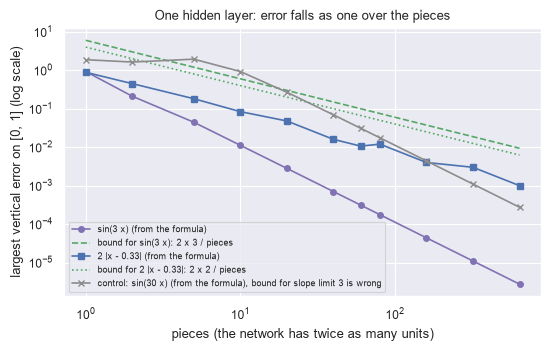

In [9]:
figure, axis = plt.subplots(figsize=(5.6, 3.6))
for name, color, marker, linestyle in (("sin(3 x)", MODEL, "o", "--"), ("2 |x - 0.33|", NEAREST, "s", ":")):
    slope_limit = targets[name][1]
    axis.plot(PIECE_COUNTS, errors_by_target[name], marker + "-", color=color, markersize=4, label=f"{name} (from the formula)")
    axis.plot(PIECE_COUNTS, [2.0 * slope_limit / piece_count for piece_count in PIECE_COUNTS], linestyle, color=BOUND,
              label=f"bound for {name}: 2 x {slope_limit:g} / pieces")
axis.plot(PIECE_COUNTS, wrong_errors, "x-", color=BEFORE, markersize=4,
          label="control: sin(30 x) (from the formula), bound for slope limit 3 is wrong")
axis.set_xscale("log")
axis.set_yscale("log")
axis.set_xlabel("pieces (the network has twice as many units)")
axis.set_ylabel("largest vertical error on [0, 1] (log scale)")
axis.set_title("One hidden layer: error falls as one over the pieces")
axis.legend(fontsize=6.5)
figure.tight_layout()
save_figure(figure, "32-error-against-pieces")
plt.show()